# Setup

In [1]:
import sys

from Part_2.course22p2.miniai.conv import def_device

sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

import pickle,gzip,math,os,time,shutil,torch,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
import fastcore.all as fc
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter,itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager

import torchvision.transforms.functional as TF,torch.nn.functional as F
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from fastcore.test import test_close


torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray'

import logging
logging.disable(logging.WARNING)

set_seed(42)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
xl,yl = 'image','label'
name = "fashion_mnist"
bs = 1024
xmean,xstd = 0.28, 0.35

@inplace
def transformi(b): b[xl] = [(TF.to_tensor(o)-xmean)/xstd for o in b[xl]]

dsd = load_dataset(name)
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=4)

In [3]:
class Accuracy100(MulticlassAccuracy):
    def compute(self):
        # Multiplies the final result by 100
        return super().compute() * 100 # here we overwrite the main function that makes the calculation but calling the original using super() , so we use the original but adjust it

# Use your new class
metrics = MetricsCB(accuracy=Accuracy100())

In [4]:
act_gr = partial(GeneralRelu, leak=0.1, sub=0.4)
astats = ActivationStats(fc.risinstance(GeneralRelu))
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), astats]
iw = partial(init_weights, leaky=0.1)

# Making a Deeper model

In [5]:
def get_model(act=nn.ReLU, nfs=(8,16,32,64,128), norm=nn.BatchNorm2d):
    layers = [conv(1,8,stride=1,act=act,norm=norm)]
    layers +=[conv(nfs[i] , nfs[i+1] , act=act,norm=norm) for i in range(len(nfs)-1)]
    return nn.Sequential(*layers, conv(nfs[-1],10,act=None,norm=norm,bias=True) , nn.Flatten()).to(def_device)

- `layer 1` -> add more channels while keeping the the same image dim (28,28) in our case

for `bias = True` :

| Situation              | bias=True Useful? | Reason                              |
|------------------------|-------------------|-------------------------------------|
| With BatchNorm         | Almost no         | BatchNorm has its own bias          |
| Without any norm       | Yes               | Very useful                         |
| Other norms            | Usually yes       | Safe / beneficial                   |



In [6]:
lr,epochs = 6e-2,5
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

accuracy,loss,epoch,train
81.028,0.688,0,train
84.070,0.501,0,eval
88.587,0.329,1,train
87.570,0.364,1,eval
90.865,0.259,2,train
89.690,0.297,2,eval
92.605,0.207,3,train
91.250,0.247,3,eval
94.372,0.164,4,train
92.280,0.223,4,eval


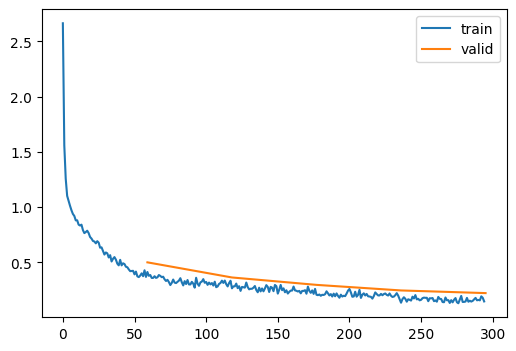

In [7]:
learn.fit(epochs)

In [8]:
xtra[0].schedo.get_last_lr()

[3.7116887232146113e-06]

# ResNet (Skip connection)

The ResNet (*residual network*) was introduced in 2015 by Kaiming He et al in the article ["Deep Residual Learning for Image Recognition"](https://arxiv.org/abs/1512.03385). The key idea is using a *skip connection* to allow deeper networks to train successfully.


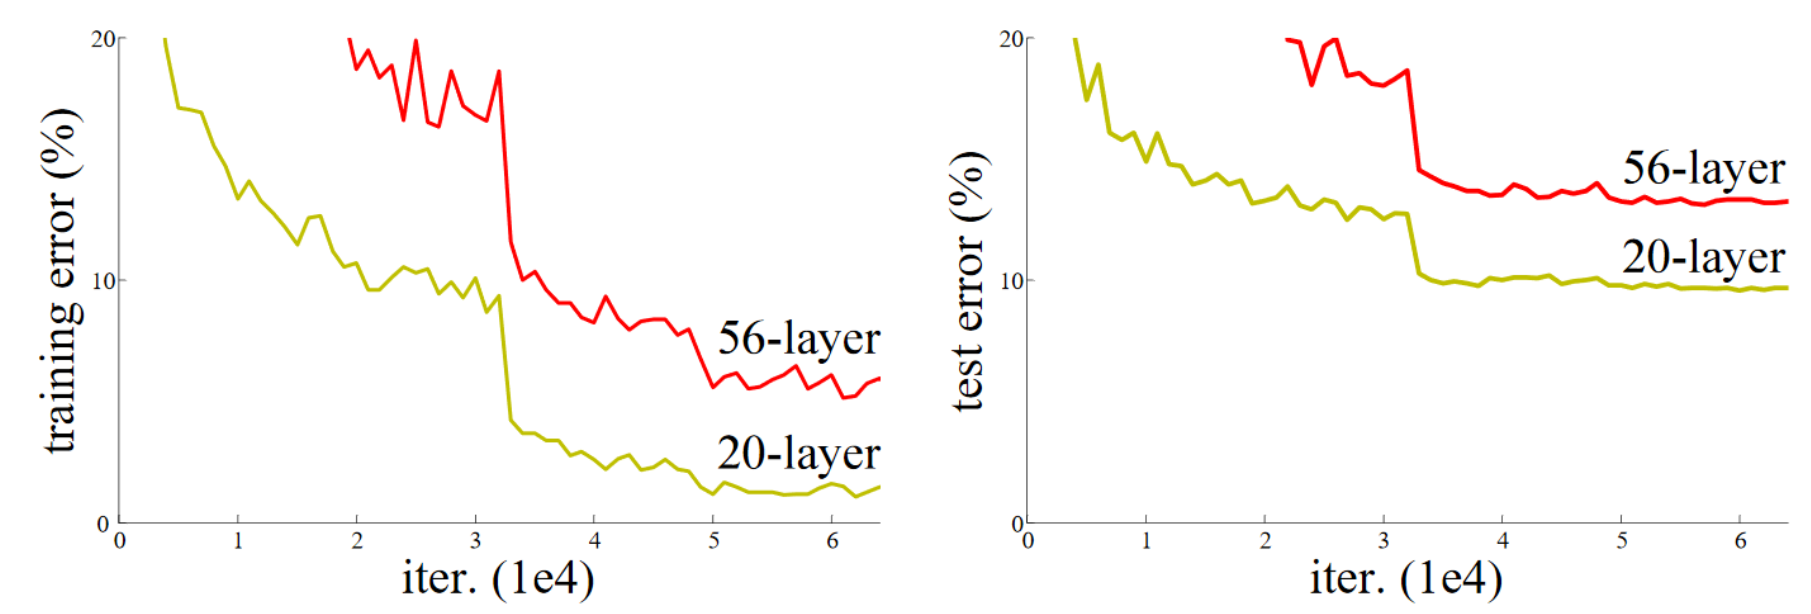

    ─────────────────────────────────────────
    1- PROBLEM: VANISHING GRADIENTS
    ─────────────────────────────────────────
    deep network: layer1 → layer2 → ... → layer100

    to update W1 we need:
    d(loss)/d(W1) = grad100 × grad99 × ... × grad1

    each grad can be < 1, so:
    0.5 × 0.5 × 0.5 × ... × 0.5 = 0.000000000001

    W1 update = W1 - lr × 0.000000000001
    W1 barely moves, learns NOTHING ✗

    the layer is not skipped , it still runs, still does math
    but does WRONG math forever -> because the signal never arrived ✗


    ─────────────────────────────────────────
    2- SOLUTION: SKIP CONNECTION
    ─────────────────────────────────────────
    output = conv_block(x) + x

    take derivative with respect to x:

    d(output)   d(conv_block(x))   d(x)
    ───────── = ──────────────── + ────
    d(x)              d(x)          d(x)
                       ↑               ↑
                  vanishing part      = 1
                  (can be tiny)       ALWAYS 1
                                      no matter what

    so at each block boundary in the chain rule:
    block_grad = (messy conv stuff) + 1

    for 3 blocks:
    total grad = (mess+1) × (mess+1) × (mess+1)
               = 1.5      × 1.5      × 1.5
               = still healthy ✓

    the +1 is injected at EVERY block boundary (because d(x)/d(x) = 1 always)
    -> early layers ALWAYS get a signal ✓


    ─────────────────────────────────────────
    3- WHY + x SPECIFICALLY
    ─────────────────────────────────────────
    same + sign does TWO jobs at once:

    FORWARD:  if conv learns nothing → output = 0 + x = x
              input image keeps flowing forward
              features dont die ✓

    BACKWARD: d(x + F(x))/d(x) = 1 + dF/dx
              the 1 always reaches early layers
              gradients dont die ✓

    one operation, two benefits ✓


    ─────────────────────────────────────────
    4- BATCHNORM AND GRADIENTS
    ─────────────────────────────────────────
    gradient w.r.t weight = gradient_from_above × activation

    if activation is huge → gradient is huge   EXPLODES ✗
    if activation is tiny → gradient is tiny   VANISHES ✗

    batchnorm forces activations → mean=0, std=1

    gradient = gradient_from_above × ~1  (grad of convs+1)
                                       ↑
                                       normalized activation
                                       never huge, never tiny ✓

    so batchnorm controls gradients DIRECTLY
    because activations are literally part of the gradient math ✓


    ─────────────────────────────────────────
    5- ZERO INIT (removed)
    ─────────────────────────────────────────
    idea: init last batchnorm weights to 0
    → conv_block output = 0 at start
    → output = act(0 + x) = act(x)
    → model starts as pure identity
    → learns gradually from there

    works for 100+ layer models
    for our ~6 layer model: makes things WORSE
    normal init is fine at shallow depth
    zero init just slows learning ✗  REMOVED


    ─────────────────────────────────────────
    6- MULTI-CHANNEL CONVOLUTION (the 72 number)
    ─────────────────────────────────────────
    going from 8 input channels → 16 output channels
    → 16 kernels -> each 8 mini-kernels of (3×3) ,  8 × 9 = 72 weights

    to compute ONE output pixel for kernel 1:

    [9 values from channel1, 9 from channel2, ... 9 from channel8]
    ←──────────────── 72 numbers total ──────────────────────────
                                  ↓  dot product
    [9 weights mini-kernel1, 9 weights mini-kernel2, ... 9 weights mini-kernel8]
    ←──────────────── 72 numbers total ──────────────────────────

        = multiply each pair, sum all 72 results = ONE pixel ✓

    this is the same as doing each mini-kernel separately and
    adding all 8 results together , but faster at one step

In [9]:
def _conv_block(ni,nf,stride,act=act_gr,norm=None,ks=3):
    return nn.Sequential(conv(ni, nf, stride=1, act=act, norm=norm, ks=ks),
                         conv(nf, nf, stride=stride, act=None, norm=norm, ks=ks))

there is no activation on conv2 , because we aer going to put one on the final output of the ResNet

In [10]:
# Make a ResNet block
class ResBlock(nn.Module):
    def __init__(self,ni,nf,stride=1,act=act_gr,norm=None,ks=3):
        super().__init__()
        self.convs = _conv_block(ni,nf,stride,act=act,norm=norm,ks=ks)
        self.idconv = fc.noop if ni==nf else conv(ni,nf,ks=1,stride=1,act=None)
        self.pool = fc.noop if stride==1 else nn.AvgPool2d(2,ceil_mode=True)
        self.act = act()

    def forward(self,x): return self.act(self.convs(x) + self.idconv(self.pool(x)))

    AVERAGE POOLING:
    ─────────────────────────────────────────
    takes 2×2 window
    averages the 4 values into 1

    input (4×4):              output (2×2):
    ┌──┬──┬──┬──┐             ┌────┬────┐
    │1 │2 │3 │4 │             │    │    │
    ├──┼──┼──┼──┤   avg pool  │2.5 │3.0 │
    │4 │3 │2 │3 │  ────────→  ├────┼────┤
    ├──┼──┼──┼──┤             │    │    │
    │1 │2 │3 │4 │             │2.5 │2.5 │
    ├──┼──┼──┼──┤             └────┴────┘
    │4 │3 │2 │1 │
    └──┴──┴──┴──┘

    ceil_mode=True:
    ─────────────────────────────────────────
    if spatial size is ODD (e.g. 7×7)
    normal pool: 7/2 = 3 (floor) → 3×3
    ceil_mode:   7/2 = 4 (ceil)  → 4×4
    keeps more information ✓

In [11]:
def get_model(act=nn.ReLU, nfs=(8,16,32,64,128,256), norm=nn.BatchNorm2d,stride=2):
    layers = [ResBlock(1,8,stride=1,act=act,norm=norm)]
    layers += [ResBlock(nfs[i],nfs[i+1],stride=stride,act=act,norm=norm) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(),nn.Linear(nfs[-1],10,bias=False) , nn.BatchNorm1d(10)]
    return nn.Sequential(*layers).to(def_device)

 `nn.BatchNorm1d` -> not absolute truth for all cases but from experimenation

    example without BN:
    logits = [1200, -800, 3400, ...]   ← huge numbers
    cross_entropy(softmax(logits))     ← numerical disaster ✗

    example with BN:
    logits = [0.3, -1.2, 2.1, ...]    ← normalized
    cross_entropy(softmax(logits))     ← stable ✓

In [12]:
# make a function that print models dims as a Hook
def _print_shape(hook, mod, inp, outp): print(type(mod).__name__, inp[0].shape, outp.shape)
model = get_model()
learn = TrainLearner(model, dls, F.cross_entropy, cbs=[DeviceCB(), SingleBatchCB()])
with Hooks(model, _print_shape) as hooks: learn.fit(1, train=False)

ResBlock torch.Size([2048, 1, 28, 28]) torch.Size([2048, 8, 28, 28])
ResBlock torch.Size([2048, 8, 28, 28]) torch.Size([2048, 16, 14, 14])
ResBlock torch.Size([2048, 16, 14, 14]) torch.Size([2048, 32, 7, 7])
ResBlock torch.Size([2048, 32, 7, 7]) torch.Size([2048, 64, 4, 4])
ResBlock torch.Size([2048, 64, 4, 4]) torch.Size([2048, 128, 2, 2])
ResBlock torch.Size([2048, 128, 2, 2]) torch.Size([2048, 256, 1, 1])
Flatten torch.Size([2048, 256, 1, 1]) torch.Size([2048, 256])
Linear torch.Size([2048, 256]) torch.Size([2048, 10])
BatchNorm1d torch.Size([2048, 10]) torch.Size([2048, 10])


In [18]:
# make it as a fancy summery with also the params numbers for each block and total params
@fc.patch
def summary(self: Learner):
    res = '|Module|Input|Output|Num params|\n|--|--|--|--|\n'
    tot = 0

    def _f(hook, mod, inp, outp):
        nonlocal res, tot
        nparms = sum(o.numel() for o in mod.parameters())
        tot += nparms
        res += f'|{type(mod).__name__}|{tuple(inp[0].shape)}|{tuple(outp.shape)}|{nparms}|\n'

    with Hooks(self.model, _f) as hooks:
        self.fit(1, lr=1, train=False, cbs=SingleBatchCB())
    print(f"Tot params: {tot:,} params" )

    if fc.IN_NOTEBOOK:  # make it as MD if in notebook
        from IPython.display import Markdown
        return Markdown(res)
    else:
        print(res)

- `tensor.numel()` → How many numbers are inside this tensor
- `len(something)` → length list / first dimension of tensor

In [19]:
TrainLearner(get_model(), dls, F.cross_entropy, cbs=DeviceCB()).summary()

Tot params: 1,228,908 params


|Module|Input|Output|Num params|
|--|--|--|--|
|ResBlock|(2048, 1, 28, 28)|(2048, 8, 28, 28)|712|
|ResBlock|(2048, 8, 28, 28)|(2048, 16, 14, 14)|3696|
|ResBlock|(2048, 16, 14, 14)|(2048, 32, 7, 7)|14560|
|ResBlock|(2048, 32, 7, 7)|(2048, 64, 4, 4)|57792|
|ResBlock|(2048, 64, 4, 4)|(2048, 128, 2, 2)|230272|
|ResBlock|(2048, 128, 2, 2)|(2048, 256, 1, 1)|919296|
|Flatten|(2048, 256, 1, 1)|(2048, 256)|0|
|Linear|(2048, 256)|(2048, 10)|2560|
|BatchNorm1d|(2048, 10)|(2048, 10)|20|


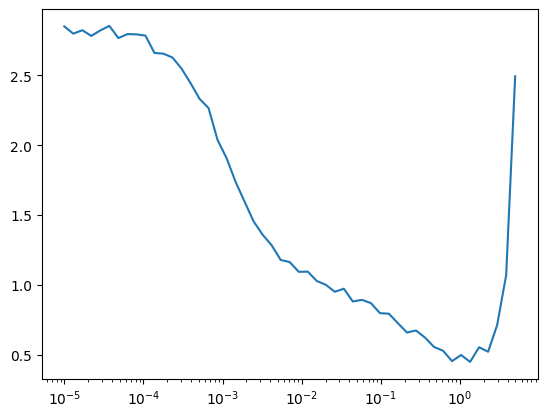

In [15]:
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
MomentumLearner(model, dls, F.cross_entropy, cbs=DeviceCB()).lr_find()

In [16]:
lr = 2e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

accuracy,loss,epoch,train
81.920,0.703,0,train
85.040,0.493,0,eval
89.285,0.349,1,train
84.680,0.469,1,eval
91.538,0.253,2,train
89.700,0.303,2,eval
93.408,0.197,3,train
92.200,0.226,3,eval
95.170,0.149,4,train
92.930,0.212,4,eval


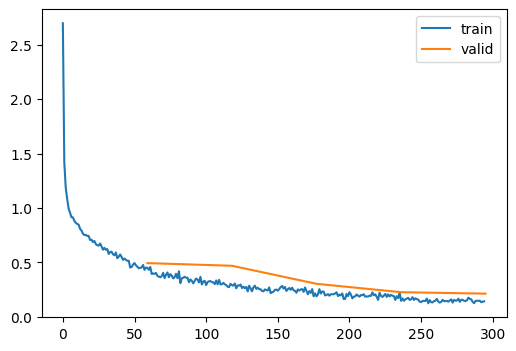

In [17]:
learn.fit(epochs)

# Using other timm ResNet models

In [20]:
import timm
from timm.models.resnet import BasicBlock, ResNet, Bottleneck

In [21]:
' '.join(timm.list_models('*resnet*')) # here are all resnet models

'cspresnet50 cspresnet50d cspresnet50w eca_resnet33ts ecaresnet26t ecaresnet50d ecaresnet50d_pruned ecaresnet50t ecaresnet101d ecaresnet101d_pruned ecaresnet200d ecaresnet269d ecaresnetlight gcresnet33ts gcresnet50t inception_resnet_v2 lambda_resnet26rpt_256 lambda_resnet26t lambda_resnet50ts legacy_seresnet18 legacy_seresnet34 legacy_seresnet50 legacy_seresnet101 legacy_seresnet152 nf_ecaresnet26 nf_ecaresnet50 nf_ecaresnet101 nf_resnet26 nf_resnet50 nf_resnet101 nf_seresnet26 nf_seresnet50 nf_seresnet101 resnet10t resnet14t resnet18 resnet18d resnet26 resnet26d resnet26t resnet32ts resnet33ts resnet34 resnet34d resnet50 resnet50_clip resnet50_clip_gap resnet50_gn resnet50_mlp resnet50c resnet50d resnet50s resnet50t resnet50x4_clip resnet50x4_clip_gap resnet50x16_clip resnet50x16_clip_gap resnet50x64_clip resnet50x64_clip_gap resnet51q resnet61q resnet101 resnet101_clip resnet101_clip_gap resnet101c resnet101d resnet101s resnet152 resnet152c resnet152d resnet152s resnet200 resnet200d 

In [22]:
model = timm.create_model('resnet18d', in_chans=1, num_classes=10)
# model = ResNet(in_chans=1, block=BasicBlock, layers=[2,2,2,2], stem_width=32, avg_down=True)

In [23]:
lr = 2e-2
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched)]
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)

accuracy,loss,epoch,train
78.012,0.638,0,train
68.600,2.004,0,eval
87.772,0.327,1,train
86.060,0.416,1,eval
90.950,0.245,2,train
87.820,0.343,2,eval
92.810,0.191,3,train
91.400,0.241,3,eval
94.695,0.143,4,train
92.250,0.219,4,eval


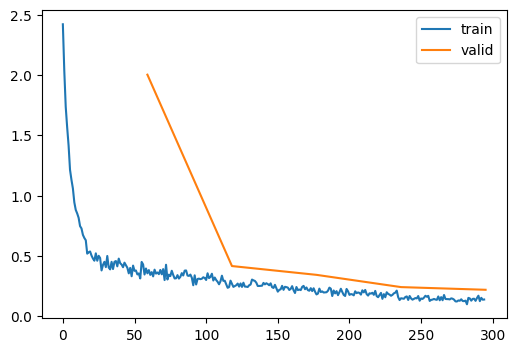

In [24]:
learn.fit(epochs)

In [ ]:
s